# Аудит A/B-теста (Домашнее задание №2)

**Задача:** проверить эксперимент, в котором аналитик, предположительно, нарушил протокол,
найти скрытые проблемы в данных и решить, внедрять ли фичу.

**Данные:** `exp_data_seed_4843151.csv` (генератор — `data_generation/generate_data.py`, seed = 4843151).

Структура:
1. Загрузка и базовая информация
2. Pre-launch checks: SRM и баланс ковариат
3. Первичная метрика `converted` (без вывода о значимости)
4. Проверки корректности: guardrail, сегменты с поправкой, peeking
5. Коррекция оценки эффекта (стратификация, регрессия, IPW, CUPED)
6. Финальное решение

Уровень значимости везде α = 0.05.

In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportion_effectsize,
    proportions_ztest,
)

MY_SEED = 4843151
DATA_PATH = Path(f"exp_data_seed_{MY_SEED}.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

ALPHA = 0.05
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)


def in_notebook() -> bool:
    """True, если код выполняется в Jupyter/IPython."""
    try:
        get_ipython  # noqa: F821
        return True
    except NameError:
        return False


if not in_notebook():
    matplotlib.use("Agg")  # в обычном скрипте графики только сохраняются в figures/


def show(fig):
    """Показать график в ноутбуке или просто закрыть его в скрипте (файл уже сохранён)."""
    if in_notebook():
        plt.show()
    else:
        plt.close(fig)


def verdict(p_value: float, yes: str, no: str, alpha: float = ALPHA) -> str:
    """Текстовый вердикт по p-value."""
    return yes if p_value < alpha else no


def two_prop_test(x_test, n_test, x_ctrl, n_ctrl, alternative="two-sided"):
    """
    Z-тест для разницы двух долей (test - control).
    Возвращает словарь с конверсиями, абсолютным и относительным lift,
    95% ДИ для разницы (Wald) и p-value.
    """
    p_t, p_c = x_test / n_test, x_ctrl / n_ctrl
    _, p_value = proportions_ztest([x_test, x_ctrl], [n_test, n_ctrl], alternative=alternative)
    ci_low, ci_high = confint_proportions_2indep(
        x_test, n_test, x_ctrl, n_ctrl, method="wald", compare="diff"
    )
    return {
        "p_test": p_t,
        "p_control": p_c,
        "abs_lift": p_t - p_c,
        "rel_lift": (p_t - p_c) / p_c if p_c > 0 else np.nan,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "p_value": p_value,
    }


def print_test(name, res):
    print(
        f"{name}: control={res['p_control']:.4f}, test={res['p_test']:.4f}, "
        f"abs lift={res['abs_lift']:+.4f} ({res['rel_lift']:+.1%}), "
        f"95% ДИ [{res['ci_low']:+.4f}; {res['ci_high']:+.4f}], p-value={res['p_value']:.4g}"
    )

## 1. Загрузка данных и базовая информация

In [2]:
df = pd.read_csv(DATA_PATH)
df["error_flag"] = df["error_flag"].astype(int)
df["is_test"] = (df["variant"] == "test").astype(int)
# entry_time хранится как доля дня (float) — переводим во время для наглядности
df["time_delta"] = pd.to_timedelta(df["entry_time"], unit="D")

print(f"Строк: {len(df)}, столбцов: {df.shape[1]}")
print(f"Пропуски: {int(df.isna().sum().sum())}, дубликаты user_id: {int(df['user_id'].duplicated().sum())}")
print(df.head())

basic = df.groupby("variant").agg(
    users=("user_id", "count"),
    conversion=("converted", "mean"),
    error_rate=("error_flag", "mean"),
    weekend_share=("weekend", "mean"),
    entry_time_mean=("entry_time", "mean"),
)
basic["share"] = basic["users"] / basic["users"].sum()
print("\nБазовая информация по группам:")
print(basic)

n_ctrl, n_test = basic.loc["control", "users"], basic.loc["test", "users"]

Строк: 6626, столбцов: 9
Пропуски: 0, дубликаты user_id: 0
   user_id  variant  converted  error_flag  weekend  platform  entry_time  is_test                time_delta
0        0  control          0           0        0         0      0.4237        0 0 days 10:10:04.782261633
1        1  control          0           0        0         1      0.4644        0 0 days 11:08:42.516235265
2        2     test          0           0        1         0      0.8373        1 0 days 20:05:46.725847958
3        3  control          0           0        0         0      0.6292        0 0 days 15:05:59.933278415
4        4  control          0           0        0         1      0.2809        0 0 days 06:44:31.127260102

Базовая информация по группам:
         users  conversion  error_rate  weekend_share  entry_time_mean  share
variant                                                                      
control   4013      0.1139      0.0192         0.1229           0.5044 0.6056
test      2613      0

## 2. Pre-launch checks

### 2.1 SRM (Sample Ratio Mismatch)
Хи-квадрат тест согласия: фактические размеры групп против ожидаемых 50/50.

In [3]:
observed = np.array([n_ctrl, n_test])
expected = np.array([0.5, 0.5]) * observed.sum()
srm_chi2, srm_p = stats.chisquare(observed, expected)

print(f"Наблюдаемо: control={n_ctrl}, test={n_test}; ожидаемо: {expected[0]:.0f} / {expected[1]:.0f}")
print(f"Доля test = {n_test / observed.sum():.2%}")
print(f"chi2 = {srm_chi2:.2f}, p-value = {srm_p:.3g}")
print("Вердикт:", verdict(srm_p, "SRM обнаружен", "SRM нет"))

Наблюдаемо: control=4013, test=2613; ожидаемо: 3313 / 3313
Доля test = 39.44%
chi2 = 295.80, p-value = 2.7e-66
Вердикт: SRM обнаружен


### 2.2 Баланс ковариат
При корректной рандомизации ковариаты не должны отличаться между группами.
Проверяем `weekend` (t-тест + хи-квадрат), `entry_time` (t-тест + U-тест Манна–Уитни)
и `platform` (хи-квадрат независимости).

In [4]:
ctrl, test = df[df["variant"] == "control"], df[df["variant"] == "test"]

balance_rows = []
for col in ["weekend", "entry_time"]:
    t_p = stats.ttest_ind(test[col], ctrl[col], equal_var=False).pvalue
    u_p = stats.mannwhitneyu(test[col], ctrl[col], alternative="two-sided").pvalue
    # Стандартизованная разница средних (SMD): |SMD| > 0.1 — заметный дисбаланс
    smd = (test[col].mean() - ctrl[col].mean()) / np.sqrt((test[col].var() + ctrl[col].var()) / 2)
    balance_rows.append(
        {"covariate": col, "control_mean": ctrl[col].mean(), "test_mean": test[col].mean(),
         "SMD": smd, "t_test_p": t_p, "U_test_p": u_p}
    )
balance = pd.DataFrame(balance_rows).set_index("covariate")
print(balance)

for col in ["weekend", "platform"]:
    ct = pd.crosstab(df[col], df["variant"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    print(f"\nХи-квадрат {col} x variant: chi2={chi2:.2f}, p-value={p:.3g}")
    print(pd.crosstab(df[col], df["variant"], normalize="columns").round(3))

# Конверсия по weekend: проверяем, что weekend влияет и на исход (условие confounder'а)
print("\nКонверсия по weekend (обе группы вместе):")
print(df.groupby("weekend")["converted"].agg(["mean", "size"]))
x = df.groupby("weekend")["converted"].sum()
n = df.groupby("weekend")["converted"].size()
print(f"p-value (weekend=1 vs weekend=0): {proportions_ztest(x.values[::-1], n.values[::-1])[1]:.3g}")

            control_mean  test_mean    SMD  t_test_p  U_test_p
covariate                                                     
weekend           0.1229     0.5771 1.0829    0.0000    0.0000
entry_time        0.5044     0.5511 0.1616    0.0000    0.0000

Хи-квадрат weekend x variant: chi2=1547.08, p-value=0
variant  control   test
weekend                
0         0.8770 0.4230
1         0.1230 0.5770

Хи-квадрат platform x variant: chi2=0.20, p-value=0.906
variant   control   test
platform                
0          0.6450 0.6460
1          0.2640 0.2660
2          0.0910 0.0880

Конверсия по weekend (обе группы вместе):
          mean  size
weekend             
0       0.1081  4625
1       0.1524  2001
p-value (weekend=1 vs weekend=0): 3.99e-07


**Вывод по pre-launch checks** (числа — из вывода выше):
* **SRM обнаружен.** Control 4013 (60.6%), test 2613 (39.4%) при ожидаемых 3313 / 3313;
  chi2 = 295.8, p-value = 2.7e-66. Распределение по группам сломано, поэтому результатам теста в таком виде доверять нельзя.
* **Confounder `weekend`.** В test 57.7% пользователей пришли в выходные, в control — 12.3%
  (SMD = 1.08, p-value ≈ 0 и в t-тесте, и в хи-квадрате). Weekend сам повышает конверсию:
  15.2% против 10.8%, p = 4e-7. Значит, часть «эффекта» в test объясняется тем,
  что туда попало больше выходных пользователей.
* **`entry_time` тоже не сбалансирован:** в test пользователи входят позже (среднее 0.551 против 0.504,
  SMD = 0.16, t-тест и U-тест p < 1e-9). Подробнее — в разделе про peeking (4.3).
* `platform` распределена между группами одинаково (p = 0.91): эта ковариата в порядке,
  и её можно использовать для сегментного анализа.

## 3. Анализ первичной метрики `converted`
Z-тест для двух пропорций, абсолютный и относительный lift, 95% ДИ для разницы.
**Вывод о значимости здесь не делаем** — сначала проверки из раздела 4.

In [5]:
x_t, x_c = test["converted"].sum(), ctrl["converted"].sum()
primary = two_prop_test(x_t, n_test, x_c, n_ctrl)
print_test("converted (наивный анализ)", primary)

# Дублируем t-тестом (на больших выборках он даёт почти то же самое)
print(f"t-тест Уэлча p-value: {stats.ttest_ind(test['converted'], ctrl['converted'], equal_var=False).pvalue:.4g}")

converted (наивный анализ): control=0.1139, test=0.1332, abs lift=+0.0193 (+16.9%), 95% ДИ [+0.0030; +0.0356], p-value=0.01876
t-тест Уэлча p-value: 0.02051


Наивный результат: конверсия 11.39% → 13.32%, lift = +1.93 п.п. (+16.9%), 95% ДИ [+0.30; +3.56] п.п., p-value = 0.019
(t-тест Уэлча даёт p = 0.021). Формально p < 0.05, но из-за SRM и confounder'а этой цифре пока доверять нельзя.

## 4. Проверки корректности

### 4.1 Guardrail: `error_flag`
Односторонняя гипотеза H1: доля ошибок в test выше, чем в control.

In [6]:
e_t, e_c = test["error_flag"].sum(), ctrl["error_flag"].sum()
guard = two_prop_test(e_t, n_test, e_c, n_ctrl, alternative="larger")
print_test("error_flag", guard)
print(f"Ошибок в test в {guard['p_test'] / guard['p_control']:.2f} раза больше")
print("Вердикт:", verdict(guard["p_value"], "Guardrail НАРУШЕН — тест нужно остановить",
                          "Guardrail в норме"))

# Проверяем, что рост ошибок не объясняется weekend (сравниваем внутри страт)
print("\nerror_flag внутри страт weekend:")
print(df.groupby(["weekend", "variant"])["error_flag"].mean().unstack())

error_flag: control=0.0192, test=0.0597, abs lift=+0.0405 (+211.1%), 95% ДИ [+0.0305; +0.0505], p-value=1.068e-18
Ошибок в test в 3.11 раза больше
Вердикт: Guardrail НАРУШЕН — тест нужно остановить

error_flag внутри страт weekend:
variant  control   test
weekend                
0         0.0179 0.0715
1         0.0284 0.0511


**Guardrail нарушен:** ошибки загрузки 1.92% в control против 5.97% в test, то есть в 3.1 раза больше
(+4.05 п.п., 95% ДИ [+3.05; +5.05], p-value = 1e-18). Рост виден в обеих стратах weekend
(будни 1.79% → 7.15%, выходные 2.84% → 5.11%), значит, его вызывает сама фича, а не перекос выборки.
По правилам guardrail-метрик **тест нужно остановить, даже если конверсия выросла**.

### 4.2 Сегментный анализ по `platform` с поправкой на множественные проверки

          n_control  n_test  p_control  p_test  abs_lift  ci_low  ci_high  p_value  p_bonferroni  p_fdr_bh  significant_after_bonf
platform                                                                                                                          
0              2589    1688     0.1116  0.1244    0.0128 -0.0071   0.0327   0.2031        0.6094    0.3047                   False
1              1060     696     0.1142  0.1236    0.0094 -0.0216   0.0405   0.5497        1.0000    0.5497                   False
2               364     229     0.1291  0.2271    0.0980  0.0337   0.1622   0.0018        0.0055    0.0055                    True

Конверсия по platform x weekend x variant:
variant           control   test
platform weekend                
0        0         0.1037 0.0960
         1         0.1688 0.1471
1        0         0.1097 0.1078
         1         0.1462 0.1335
2        0         0.1270 0.2442
         1         0.1429 0.2168


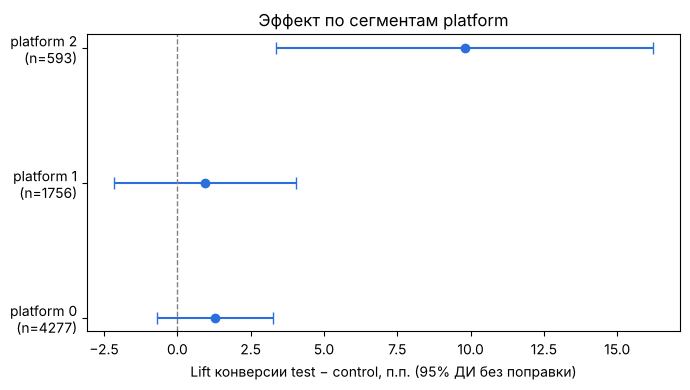

In [7]:
seg_rows = []
for plat, g in df.groupby("platform"):
    gt, gc = g[g["variant"] == "test"], g[g["variant"] == "control"]
    r = two_prop_test(gt["converted"].sum(), len(gt), gc["converted"].sum(), len(gc))
    r.update({"platform": plat, "n_control": len(gc), "n_test": len(gt)})
    seg_rows.append(r)
seg = pd.DataFrame(seg_rows).set_index("platform")

# Бонферрони (строгая, контролирует FWER) и Бенджамини–Хохберг (FDR)
seg["p_bonferroni"] = multipletests(seg["p_value"], alpha=ALPHA, method="bonferroni")[1]
seg["p_fdr_bh"] = multipletests(seg["p_value"], alpha=ALPHA, method="fdr_bh")[1]
seg["significant_after_bonf"] = seg["p_bonferroni"] < ALPHA
print(seg[["n_control", "n_test", "p_control", "p_test", "abs_lift", "ci_low", "ci_high",
           "p_value", "p_bonferroni", "p_fdr_bh", "significant_after_bonf"]])

# Тот же сегмент, но внутри одной страты weekend — проверяем, не confounder ли это
print("\nКонверсия по platform x weekend x variant:")
print(df.pivot_table(index=["platform", "weekend"], columns="variant", values="converted", aggfunc="mean"))

# График эффекта по сегментам
fig, ax = plt.subplots(figsize=(7, 4))
ypos = np.arange(len(seg))
ax.errorbar(seg["abs_lift"] * 100, ypos,
            xerr=[(seg["abs_lift"] - seg["ci_low"]) * 100, (seg["ci_high"] - seg["abs_lift"]) * 100],
            fmt="o", capsize=4, color="#2a6fdb")
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(ypos, [f"platform {p}\n(n={int(r.n_control + r.n_test)})" for p, r in seg.iterrows()])
ax.set_xlabel("Lift конверсии test − control, п.п. (95% ДИ без поправки)")
ax.set_title("Эффект по сегментам platform")
fig.tight_layout()
fig.savefig(FIG_DIR / "segments_lift.png", dpi=120)
show(fig)

**Результат по сегментам** (3 проверки, поправки Бонферрони и Бенджамини–Хохберга):

| platform | n | control | test | lift | p-value | p Бонферрони | p FDR |
|---|---|---|---|---|---|---|---|
| 0 | 4277 | 11.16% | 12.44% | +1.28 п.п. | 0.203 | 0.609 | 0.305 |
| 1 | 1756 | 11.42% | 12.36% | +0.94 п.п. | 0.550 | 1.000 | 0.550 |
| 2 | 593 | 12.91% | 22.71% | +9.80 п.п. | 0.0018 | **0.0055** | **0.0055** |

* После поправки значим только **platform 2**: lift +9.8 п.п., 95% ДИ [+3.4; +16.2].
* На platform 0 и 1 эффекта нет. Если сравнивать внутри одной страты weekend, конверсия test там даже немного ниже control
  (например, platform 0: будни 9.6% против 10.4%). Видимый плюс на этих платформах создаёт перекос по weekend.
* На platform 2 эффект держится в обеих стратах weekend (будни 24.4% против 12.7%, выходные 21.7% против 14.3%).

**Почему сегментный анализ не может быть единственным основанием для запуска:**
1. Чем больше срезов, тем выше шанс найти «значимый» сегмент случайно: при 3 сегментах и α = 0.05
   вероятность хотя бы одного ложного срабатывания без поправки 1 − 0.95³ ≈ 14%, при 20 сегментах ≈ 64%.
2. Гипотезу про platform 2 не заявляли заранее, это поиск после факта (HARKing).
   Такой результат — только гипотеза для нового теста.
3. Сегмент маленький (593 пользователя, из них 229 в test), ДИ широкий (от +3.4 до +16.2 п.п.), оценка нестабильна.
4. Внутри сегмента остаются проблемы всего теста: SRM, peeking и рост ошибок. Поправка на множественные проверки их не лечит.
5. Решение принимается для всего продукта. Запуск для всех из-за 9% аудитории при нулевом эффекте на остальных 91%
   и в 3 раза большем числе ошибок не оправдан.

### 4.3 Неявный peeking: связь `entry_time` и варианта

Среднее entry_time: control=0.504, test=0.551
Медиана entry_time: control=0.514, test=0.595
KS-тест: D=0.089, p-value=2.19e-11
U-тест (test позже control): p-value=7.16e-11

Доля test по децилям времени входа:
                mean  size
time_bin                  
(-0.001, 0.1] 0.3283   597
(0.1, 0.2]    0.3539   616
(0.2, 0.3]    0.3807   641
(0.3, 0.4]    0.3438   573
(0.4, 0.5]    0.3828   627
(0.5, 0.6]    0.3487   651
(0.6, 0.7]    0.4414   734
(0.7, 0.8]    0.4418   713
(0.8, 0.9]    0.4474   722
(0.9, 1.0]    0.4375   752
Хи-квадрат time_bin x variant: p-value=9.05e-09
Logit is_test ~ entry_time: coef=0.558, p-value=1.66e-10

Доля «подсмотров», где p < 0.05: 54.8%; впервые p < 0.05 на 3300 пользователях


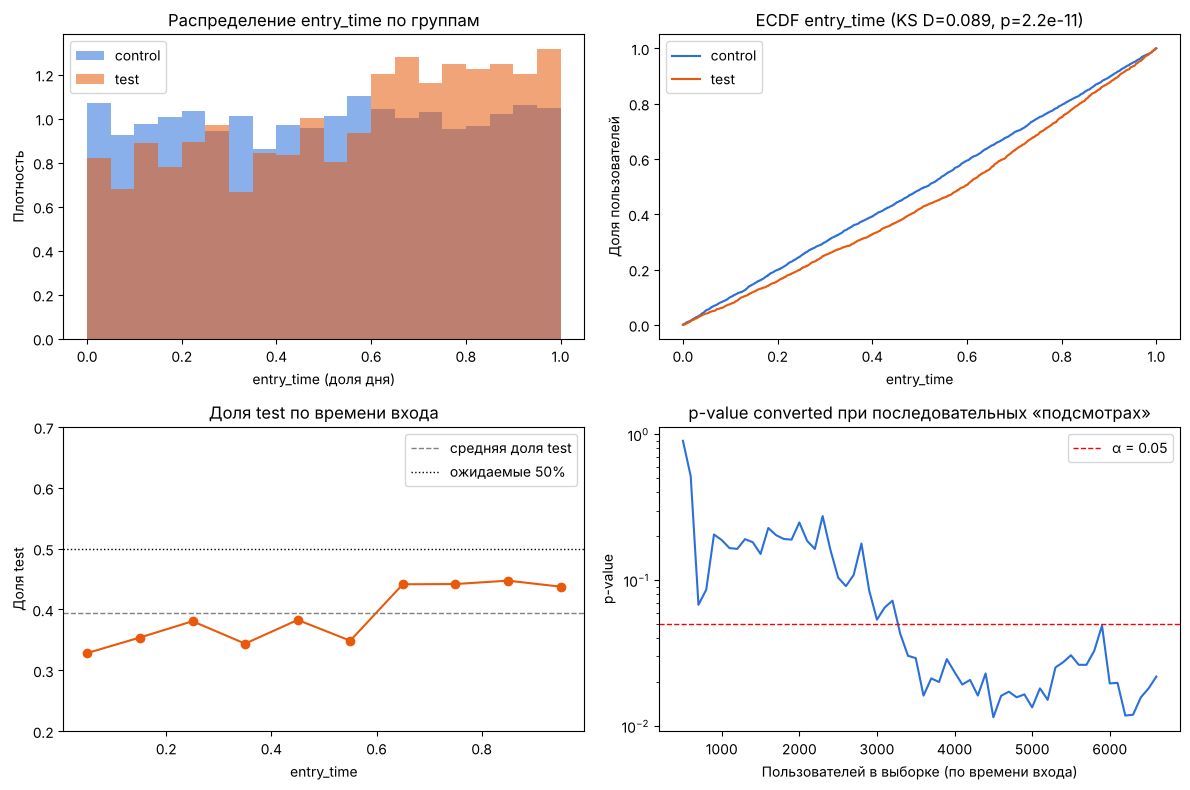

In [8]:
ks = stats.ks_2samp(test["entry_time"], ctrl["entry_time"])
mw = stats.mannwhitneyu(test["entry_time"], ctrl["entry_time"], alternative="greater")
print(f"Среднее entry_time: control={ctrl['entry_time'].mean():.3f}, test={test['entry_time'].mean():.3f}")
print(f"Медиана entry_time: control={ctrl['entry_time'].median():.3f}, test={test['entry_time'].median():.3f}")
print(f"KS-тест: D={ks.statistic:.3f}, p-value={ks.pvalue:.3g}")
print(f"U-тест (test позже control): p-value={mw.pvalue:.3g}")

# Доля test в каждом временном интервале: при честном сплите она постоянна
df["time_bin"] = pd.cut(df["entry_time"], bins=np.linspace(0, 1, 11), include_lowest=True)
share_by_time = df.groupby("time_bin", observed=True)["is_test"].agg(["mean", "size"])
print("\nДоля test по децилям времени входа:")
print(share_by_time)
chi2_t, p_t, _, _ = stats.chi2_contingency(pd.crosstab(df["time_bin"], df["variant"]))
print(f"Хи-квадрат time_bin x variant: p-value={p_t:.3g}")

# Логистическая регрессия variant ~ entry_time
logit_time = smf.logit("is_test ~ entry_time", data=df).fit(disp=0)
print(f"Logit is_test ~ entry_time: coef={logit_time.params['entry_time']:.3f}, "
      f"p-value={logit_time.pvalues['entry_time']:.3g}")

# Как менялся бы p-value первичной метрики, если бы его смотрели по мере набора пользователей
df_sorted = df.sort_values("entry_time").reset_index(drop=True)
checkpoints = np.arange(500, len(df_sorted) + 1, 100)
cum_p = []
for k in checkpoints:
    s = df_sorted.iloc[:k]
    xs = s.groupby("is_test")["converted"].agg(["sum", "size"])
    if len(xs) < 2:
        cum_p.append(np.nan)
        continue
    cum_p.append(proportions_ztest(xs["sum"].values[::-1], xs["size"].values[::-1])[1])
cum_p = np.array(cum_p)
first_sig = checkpoints[np.argmax(cum_p < ALPHA)] if (cum_p < ALPHA).any() else None
print(f"\nДоля «подсмотров», где p < 0.05: {(cum_p < ALPHA).mean():.1%}; "
      f"впервые p < 0.05 на {first_sig} пользователях")

# Графики: гистограмма, ECDF, доля test по времени, накопленный p-value
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
bins = np.linspace(0, 1, 21)
for name, g, color in [("control", ctrl, "#2a6fdb"), ("test", test, "#e8590c")]:
    axes[0, 0].hist(g["entry_time"], bins=bins, alpha=0.55, density=True, label=name, color=color)
    xs = np.sort(g["entry_time"])
    axes[0, 1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), label=name, color=color)
axes[0, 0].set(title="Распределение entry_time по группам", xlabel="entry_time (доля дня)", ylabel="Плотность")
axes[0, 1].set(title=f"ECDF entry_time (KS D={ks.statistic:.3f}, p={ks.pvalue:.1e})",
               xlabel="entry_time", ylabel="Доля пользователей")
axes[0, 0].legend(); axes[0, 1].legend()

mids = [iv.mid for iv in share_by_time.index]
axes[1, 0].plot(mids, share_by_time["mean"], "o-", color="#e8590c")
axes[1, 0].axhline(n_test / len(df), color="grey", ls="--", lw=1, label="средняя доля test")
axes[1, 0].axhline(0.5, color="black", ls=":", lw=1, label="ожидаемые 50%")
axes[1, 0].set(title="Доля test по времени входа", xlabel="entry_time", ylabel="Доля test", ylim=(0.2, 0.7))
axes[1, 0].legend()

axes[1, 1].plot(checkpoints, cum_p, color="#2a6fdb")
axes[1, 1].axhline(ALPHA, color="red", ls="--", lw=1, label="α = 0.05")
axes[1, 1].set(title="p-value converted при последовательных «подсмотрах»",
               xlabel="Пользователей в выборке (по времени входа)", ylabel="p-value", yscale="log")
axes[1, 1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "entry_time_peeking.png", dpi=120)
show(fig)

**Вывод по peeking:**
* Пользователи test входят в эксперимент систематически позже: среднее entry_time 0.551 против 0.504,
  медиана 0.595 против 0.514. KS-тест D = 0.089, p = 2.2e-11; U-тест p = 7.2e-11;
  логистическая регрессия variant ~ entry_time: coef = 0.56, p = 1.7e-10.
* В первых 60% времени доля test держится на уровне 33–38%, а в последних 40% скачком поднимается до 44–45%
  (хи-квадрат time_bin × variant, p = 9e-9). При честном сплите эта доля была бы ровной.
  Похоже, ближе к концу в test «доливали» трафик и тест продлевали, пока результат не стал значимым.
  Это и есть неявное подглядывание с остановкой теста по времени.
* График накопленного p-value: значимость появляется только после ≈3300 пользователей (половина выборки),
  и p < 0.05 выполняется лишь в 55% «подсмотров». Если остановиться при первом p < 0.05, реальная вероятность
  ложного срабатывания будет намного выше заявленных 5%.

## 5. Исправление: можно ли спасти оценку эффекта?

Нарушения: **SRM**, **confounder weekend**, **peeking по entry_time**, **нарушенный guardrail**.
Перекос по наблюдаемым ковариатам (weekend, entry_time, platform) можно скорректировать статистически.
Ниже сравниваем четыре метода с наивной оценкой.

In [9]:
corr = {}

# 0) Наивная оценка
corr["Наивная (Z-тест)"] = (primary["abs_lift"], primary["ci_low"], primary["ci_high"], primary["p_value"])

# 1) Стратификация по weekend: средневзвешенная разница внутри страт
#    (веса — доля страты во всей выборке), дисперсия — сумма дисперсий страт с весами²
strata = []
for w, g in df.groupby("weekend"):
    gt, gc = g[g["is_test"] == 1]["converted"], g[g["is_test"] == 0]["converted"]
    diff = gt.mean() - gc.mean()
    var = gt.var() / len(gt) + gc.var() / len(gc)
    strata.append((len(g) / len(df), diff, var))
    print(f"weekend={w}: control={gc.mean():.4f}, test={gt.mean():.4f}, diff={diff:+.4f}")
w_, d_, v_ = map(np.array, zip(*strata))
strat_eff, strat_se = (w_ * d_).sum(), np.sqrt((w_ ** 2 * v_).sum())
strat_p = 2 * stats.norm.sf(abs(strat_eff / strat_se))
corr["Стратификация по weekend"] = (strat_eff, strat_eff - 1.96 * strat_se, strat_eff + 1.96 * strat_se, strat_p)

# 2) Регрессионная корректировка (линейная вероятностная модель, робастные SE HC1)
ols = smf.ols("converted ~ is_test + weekend + entry_time + C(platform)", data=df).fit(cov_type="HC1")
ci = ols.conf_int().loc["is_test"]
corr["Регрессия (OLS + ковариаты)"] = (ols.params["is_test"], ci[0], ci[1], ols.pvalues["is_test"])

# 3) IPW: propensity score P(test | weekend, entry_time, platform) по логистической регрессии
ps_model = smf.logit("is_test ~ weekend + entry_time + C(platform)", data=df).fit(disp=0)
df["ps"] = ps_model.predict(df).clip(0.01, 0.99)
df["ipw"] = np.where(df["is_test"] == 1, 1 / df["ps"], 1 / (1 - df["ps"]))
# Взвешенная регрессия converted ~ is_test = разница взвешенных средних (оценка ATE)
wls = smf.wls("converted ~ is_test", data=df, weights=df["ipw"]).fit(cov_type="HC1")
ci = wls.conf_int().loc["is_test"]
corr["IPW (weekend, entry_time, platform)"] = (wls.params["is_test"], ci[0], ci[1], wls.pvalues["is_test"])

# Проверяем, что после взвешивания weekend сбалансирован
for col in ["weekend", "entry_time"]:
    m = df.groupby("is_test").apply(lambda g: np.average(g[col], weights=g["ipw"]), include_groups=False)
    print(f"После IPW: среднее {col} control={m[0]:.3f}, test={m[1]:.3f}")
print(f"Диапазон весов IPW: {df['ipw'].min():.2f} – {df['ipw'].max():.2f}")

# 4) CUPED с weekend как «предэкспериментальной» ковариатой: Y_cuped = Y - θ(X - E[X])
theta = np.cov(df["converted"], df["weekend"])[0, 1] / df["weekend"].var()
df["converted_cuped"] = df["converted"] - theta * (df["weekend"] - df["weekend"].mean())
ct_, cc_ = df.loc[df["is_test"] == 1, "converted_cuped"], df.loc[df["is_test"] == 0, "converted_cuped"]
cuped_eff = ct_.mean() - cc_.mean()
cuped_se = np.sqrt(ct_.var() / len(ct_) + cc_.var() / len(cc_))
corr["CUPED (X = weekend)"] = (cuped_eff, cuped_eff - 1.96 * cuped_se, cuped_eff + 1.96 * cuped_se,
                               2 * stats.norm.sf(abs(cuped_eff / cuped_se)))
print(f"θ (CUPED) = {theta:.4f}")

corr_df = pd.DataFrame(corr, index=["effect", "ci_low", "ci_high", "p_value"]).T
corr_df["effect_pp"] = corr_df["effect"] * 100
print("\nСравнение оценок эффекта на converted (все пользователи):")
print(corr_df)

weekend=0: control=0.1074, test=0.1104, diff=+0.0030
weekend=1: control=0.1602, test=0.1499, diff=-0.0104
После IPW: среднее weekend control=0.302, test=0.302
После IPW: среднее entry_time control=0.523, test=0.522
Диапазон весов IPW: 1.21 – 5.69
θ (CUPED) = 0.0443

Сравнение оценок эффекта на converted (все пользователи):
                                     effect  ci_low  ci_high  p_value  effect_pp
Наивная (Z-тест)                     0.0193  0.0030   0.0356   0.0188     1.9300
Стратификация по weekend            -0.0010 -0.0195   0.0175   0.9136    -0.1025
Регрессия (OLS + ковариаты)          0.0005 -0.0182   0.0191   0.9612     0.0462
IPW (weekend, entry_time, platform)  0.0011 -0.0179   0.0200   0.9112     0.1079
CUPED (X = weekend)                 -0.0008 -0.0171   0.0155   0.9204    -0.0831


### 5.1 Чувствительность: эффект без сегмента platform 2
Общий lift почти целиком дают 593 пользователя platform 2. Проверим, что остаётся без них.

Регрессия без platform 2: effect=-0.0096, 95% ДИ [-0.0286; +0.0094], p-value=0.321
Взаимодействие test x platform 2: coef=+0.0825, p-value=0.0165


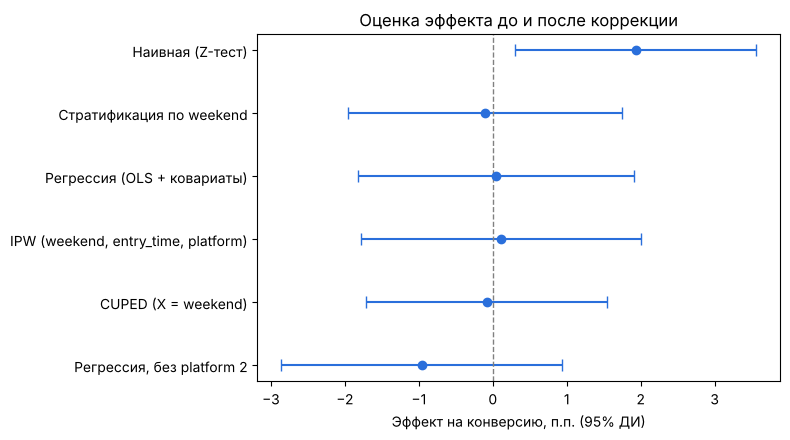

In [10]:
df_np2 = df[df["platform"] != 2]
ols_np2 = smf.ols("converted ~ is_test + weekend + entry_time + C(platform)", data=df_np2).fit(cov_type="HC1")
ci = ols_np2.conf_int().loc["is_test"]
print(f"Регрессия без platform 2: effect={ols_np2.params['is_test']:+.4f}, "
      f"95% ДИ [{ci[0]:+.4f}; {ci[1]:+.4f}], p-value={ols_np2.pvalues['is_test']:.3g}")
corr_df.loc["Регрессия, без platform 2"] = [ols_np2.params["is_test"], ci[0], ci[1],
                                            ols_np2.pvalues["is_test"], ols_np2.params["is_test"] * 100]

# Регрессия с взаимодействием test x platform: отличается ли эффект на platform 2
ols_int = smf.ols("converted ~ is_test * C(platform) + weekend + entry_time", data=df).fit(cov_type="HC1")
print(f"Взаимодействие test x platform 2: coef={ols_int.params['is_test:C(platform)[T.2]']:+.4f}, "
      f"p-value={ols_int.pvalues['is_test:C(platform)[T.2]']:.3g}")

# График: наивная и скорректированные оценки
fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(corr_df))[::-1]
ax.errorbar(corr_df["effect"] * 100, ypos,
            xerr=[(corr_df["effect"] - corr_df["ci_low"]) * 100, (corr_df["ci_high"] - corr_df["effect"]) * 100],
            fmt="o", capsize=4, color="#2a6fdb")
ax.axvline(0, color="grey", ls="--", lw=1)
ax.set_yticks(ypos, corr_df.index)
ax.set_xlabel("Эффект на конверсию, п.п. (95% ДИ)")
ax.set_title("Оценка эффекта до и после коррекции")
fig.tight_layout()
fig.savefig(FIG_DIR / "corrected_effects.png", dpi=120)
show(fig)

**Вывод по коррекции:**

| Метод | Эффект, п.п. | 95% ДИ | p-value |
|---|---|---|---|
| Наивный Z-тест | +1.93 | [+0.30; +3.56] | 0.019 |
| Стратификация по weekend | −0.10 | [−1.95; +1.75] | 0.91 |
| Регрессия (weekend, entry_time, platform) | +0.05 | [−1.82; +1.91] | 0.96 |
| IPW (weekend, entry_time, platform) | +0.11 | [−1.79; +2.00] | 0.91 |
| CUPED (X = weekend) | −0.08 | [−1.71; +1.55] | 0.92 |
| Регрессия без platform 2 | −0.96 | [−2.86; +0.94] | 0.32 |

* После учёта weekend весь наивный эффект исчезает: от +1.93 п.п. остаётся −0.1…+0.1 п.п., p > 0.9.
  Внутри страт разница почти нулевая: будни +0.30 п.п., выходные −1.04 п.п.
  Значит, «рост» конверсии объяснялся тем, что в test попало в 4.7 раза больше выходных пользователей.
* IPW балансирует ковариаты (weekend 30.2% / 30.2%, entry_time 0.523 / 0.522; веса 1.2–5.7) и даёт тот же ноль.
* Без platform 2 скорректированный эффект даже отрицательный (−0.96 п.п., незначимо). Отличие platform 2
  от остальных подтверждает взаимодействие test × platform 2 (+8.3 п.п., p = 0.017).
* IPW и регрессия убирают дисбаланс только по **наблюдаемым** ковариатам. Они не могут:
  1. исправить SRM: неизвестно, почему сплит получился 60.6/39.4. Если пользователи терялись неслучайно
     (например, из-за тех же ошибок загрузки), остаётся ненаблюдаемый перекос;
  2. отменить подглядывание: момент остановки выбран по данным, и p-value искажены;
  3. исправить guardrail: рост ошибок в 3 раза — свойство самой фичи.

Скорректированная оценка — ориентир, и она говорит, что **эффекта на конверсию нет**.
**Эксперимент невалиден, его нужно перезапустить.**

## 6. Финальное решение

In [11]:
# Сколько пользователей нужно на группу, чтобы честно поймать lift +1 п.п. от базы control
base = primary["p_control"]
mde = 0.01
n_per_group = NormalIndPower().solve_power(
    effect_size=proportion_effectsize(base + mde, base), alpha=ALPHA, power=0.8, ratio=1.0
)
print(f"Нужно ≈ {np.ceil(n_per_group):.0f} пользователей на группу для MDE = +{mde * 100:.0f} п.п. "
      f"(база {base:.2%}, power 80%); сейчас в control {n_ctrl}, в test {n_test}.")

checks = pd.DataFrame(
    [
        ["SRM", f"p = {srm_p:.1e}", verdict(srm_p, "нарушение", "ок")],
        ["Баланс weekend", f"{ctrl['weekend'].mean():.1%} vs {test['weekend'].mean():.1%}, "
                           f"p = {balance.loc['weekend', 't_test_p']:.1e}",
         verdict(balance.loc["weekend", "t_test_p"], "confounder", "ок")],
        ["Peeking (entry_time)", f"KS p = {ks.pvalue:.1e}", verdict(ks.pvalue, "нарушение", "ок")],
        ["Guardrail error_flag", f"{guard['p_control']:.2%} → {guard['p_test']:.2%}, p = {guard['p_value']:.1e}",
         verdict(guard["p_value"], "НАРУШЕН", "ок")],
        ["Наивный lift", f"{primary['abs_lift'] * 100:+.2f} п.п., p = {primary['p_value']:.3f}", "смещён"],
        ["Скорректированный lift (OLS)",
         f"{corr_df.loc['Регрессия (OLS + ковариаты)', 'effect'] * 100:+.2f} п.п., "
         f"p = {corr_df.loc['Регрессия (OLS + ковариаты)', 'p_value']:.2f}",
         verdict(corr_df.loc["Регрессия (OLS + ковариаты)", "p_value"], "значим", "незначим")],
        ["platform 2 (Бонферрони)", f"p_adj = {seg.loc[2, 'p_bonferroni']:.3f}", "гипотеза для нового теста"],
    ],
    columns=["Проверка", "Результат", "Статус"],
)
print(checks.to_string(index=False))
print("\nРЕШЕНИЕ: НЕ ROLLOUT сейчас → ПОВТОРИТЬ С ИЗМЕНЕНИЯМИ (после исправления ошибок загрузки).")

Нужно ≈ 16437 пользователей на группу для MDE = +1 п.п. (база 11.39%, power 80%); сейчас в control 4013, в test 2613.
                    Проверка                   Результат                    Статус
                         SRM                 p = 2.7e-66                 нарушение
              Баланс weekend 12.3% vs 57.7%, p = 0.0e+00                confounder
        Peeking (entry_time)              KS p = 2.2e-11                 нарушение
        Guardrail error_flag  1.92% → 5.97%, p = 1.1e-18                   НАРУШЕН
                Наивный lift       +1.93 п.п., p = 0.019                    смещён
Скорректированный lift (OLS)        +0.05 п.п., p = 0.96                  незначим
     platform 2 (Бонферрони)               p_adj = 0.006 гипотеза для нового теста

РЕШЕНИЕ: НЕ ROLLOUT сейчас → ПОВТОРИТЬ С ИЗМЕНЕНИЯМИ (после исправления ошибок загрузки).


### Продуктовый вывод

**Решение: не запускать фичу (не rollout) и повторить эксперимент с изменениями.**

Обоснование:
1. **Guardrail нарушен — это блокер.** Ошибки загрузки выросли с 1.92% до 5.97% (в 3.1 раза, p = 1e-18).
   Даже если бы конверсия выросла, ошибки у пользователей — прямой ущерб продукту.
2. **Наивный рост конверсии — артефакт.** +1.93 п.п. (p = 0.019) получились за счёт перекоса по weekend
   (57.7% выходных в test против 12.3% в control). После коррекции эффект от −0.10 до +0.11 п.п. (p > 0.9),
   без platform 2 он −0.96 п.п.
3. **Сам дизайн теста невалиден:** SRM 60.6/39.4 (p = 2.7e-66) и признаки подглядывания
   (доля test растёт с ≈35% до ≈44% к концу теста, KS p = 2.2e-11). Статистикой это не исправить.
4. **Сигнал на platform 2** (+9.8 п.п., p_adj = 0.0055) — единственный, который пережил поправку.
   Но он найден после факта, на 593 пользователях и в «грязном» тесте. Это гипотеза, а не основание для запуска.

**Что изменить при перезапуске:**
* Найти и исправить причину ошибок загрузки в тестовой версии; убедиться на канареечном релизе,
  что error_flag в test не выше, чем в control.
* Исправить сплит: детерминированное хэширование `user_id` 50/50 с одинаковой логикой для всех дней недели
  и всего периода; ежедневный автоматический SRM-мониторинг (алерт при p < 0.001).
* Зафиксировать дизайн заранее: метрику, MDE, размер выборки и длительность. Для MDE +1 п.п. от базы 11.4%
  (α = 0.05, power = 80%) нужно ≈ 16 440 пользователей на группу — сейчас в 4–6 раз меньше.
  Длительность — полные недели, чтобы будни и выходные попали в обе группы одинаково.
* Не смотреть на p-value до конца теста или сразу использовать последовательный дизайн
  (alpha-spending O'Brien–Fleming, mSPRT), если промежуточные проверки нужны.
* Гипотезу про platform 2 заранее заявить отдельной (или провести отдельный тест на этой платформе),
  а на все вторичные срезы применять поправку на множественные проверки.